# Random Forest classification of landmass
The notebook loads a satelite dataset consisting of 1 label (the first dimension of the csv) and 8 features (the final 8 dimensions). Then it trains a random forest classifier using bootstrap sampling and testing each dimension in every iteration when calculating the optimal split (most information gain).

Then the notebook compares the performance of the random forest with a deep neural network classifier (sigmoid activation function in the output layer). 

The results are in favor of a deep neural network: While both models obtains about 75%-80% accuracy on validation data. This is simply because the water class is so abundant, that always choosing this yields high accuracy.

Two maps of denmark are also produced which plots the models predictions on a dataset without labels. The cool thing is that the map is clearly recognisable as sjælland (sealand). When looking at the maps the superiority of NN is clear.

In [14]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.preprocessing import LabelEncoder
from pathlib import Path
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch


import scienceplots 
plt.style.use(["science", "grid"])
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "figure.titlesize": 15,
})

(5000000, 10)


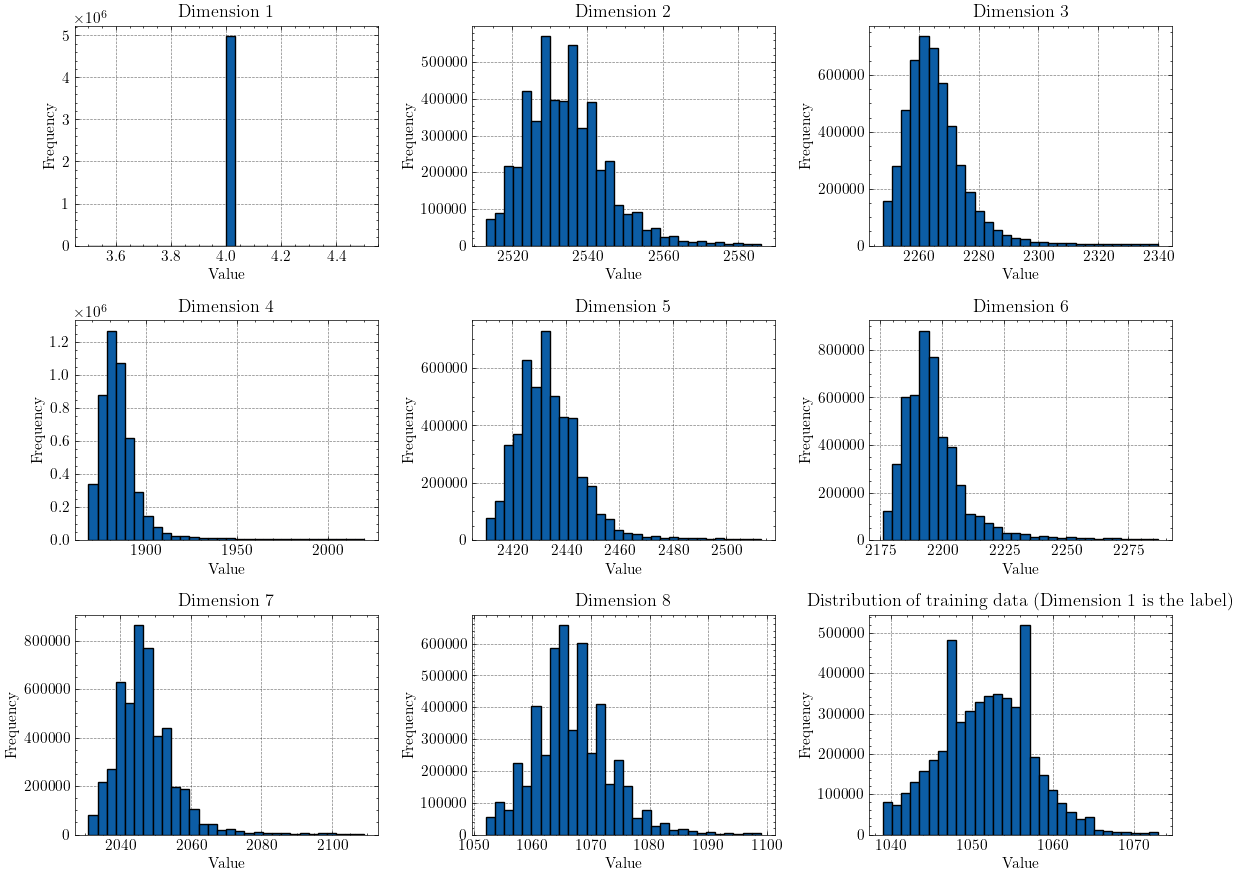

In [15]:
train = pd.read_csv('data/landsat_train.csv',header=None)
print(train.shape)

# plot dimension histograms (remove 1. and 99. percentile outliers)
fig, axes = plt.subplots(3, 3, figsize=(12, 9))

for i, ax in enumerate(axes.flat):
    x = train.iloc[:, i]
    x = x[x.between(x.quantile(0.01), x.quantile(0.99))]

    ax.hist(x, bins=30, edgecolor='black')
    ax.set_title(f'Dimension {i+1}')
    ax.set_xlabel('Value')
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.title("Distribution of training data (Dimension 1 is the label)")
plt.show()

In [16]:
# training data
X_train = train.iloc[:,1:].copy()

# very non-balanced datalabels
y_train = train.iloc[:,0].copy()
display(y_train.value_counts())
del train

0
4    4979864
6      16609
3       1646
7       1581
2        266
8         21
5         13
Name: count, dtype: int64

In [17]:
# validation data
val = pd.read_csv('data/landsat_validation.csv', header=None)
y_val = val.iloc[:,0].copy()
X_val = val.iloc[:,1:].copy()
del val # free memory

In [18]:
# defining and training Random Forest for classification
rf = RandomForestClassifier(
    # Forest size
    n_estimators=50,           # Number of trees

    # Tree complexity
    max_depth=None,            # Maximum tree depth (None = unlimited)
    min_samples_split=2,    # Minimum samples required to split a node
    min_samples_leaf=1,        # Minimum samples in each leaf
    max_leaf_nodes=None,       # Maximum number of leaves per tree

    # Randomness / feature selection
    max_features="sqrt",       # "sqrt", "log2", None, int, or float
    bootstrap=True,            # Sample training observations with replacement
    max_samples=None,          # Number/fraction sampled per tree

    # Splitting criterion
    criterion="gini",          # "gini", "entropy", or "log_loss"

    # Class weighting
    class_weight=None,         # None, "balanced", "balanced_subsample", or dict

    # Training options
    oob_score=False,           # Out-of-bag validation (requires bootstrap=True)
    n_jobs=-1,                 # -1 = use all CPU cores
    random_state=69,           # Reproducibility
    verbose=0,                 # Training output
)

# train
_ = rf.fit(X_train, y_train)

In [19]:
# predict
y_pred = rf.predict(X_val)
y_prob = rf.predict_proba(X_val)

# evaluate
print("Accuracy:", rf.score(X_val, y_val))

Accuracy: 0.7475804120824404


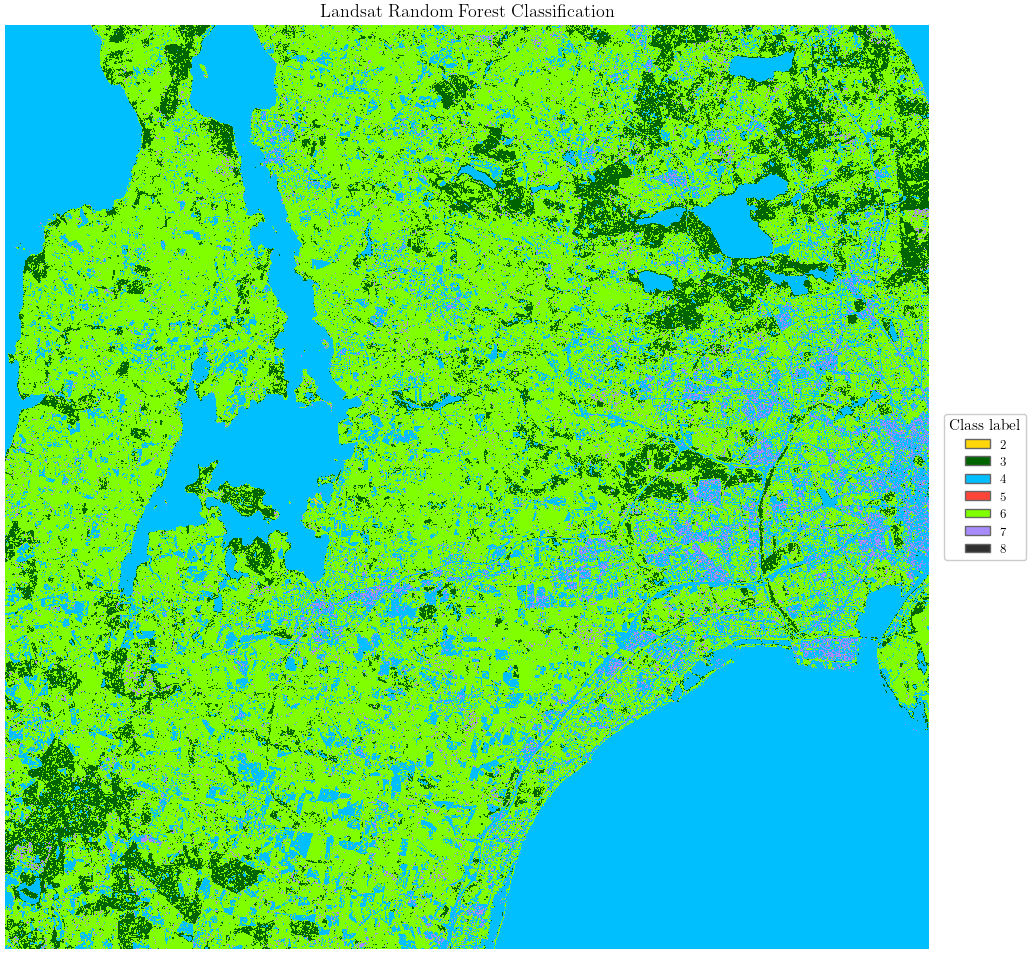

In [20]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch

# Exact class-to-color mapping from your screenshot
class_colors = {
    2: '#FFD60A',
    3: "darkgreen",
    4: '#00BFFF',
    5: '#FF453A',
    6: '#7FFF00',
    7: '#A78BFA',
    8: '#303030',
}

# Predict original class labels
unknown_area = pd.read_csv('data/landsat_area.csv', header=None)
predictions = np.asarray(rf.predict(unknown_area))

unexpected = set(np.unique(predictions)) - set(class_colors)
if unexpected:
    raise ValueError(f'No color defined for classes: {sorted(unexpected)}')

# Look up RGB colors using the ORIGINAL class numbers
rgb_lookup = np.zeros((max(class_colors) + 1, 3), dtype=np.uint8)

for label, color in class_colors.items():
    rgb_lookup[label] = np.rint(
        np.array(to_rgb(color)) * 255
    ).astype(np.uint8)

class_ids = predictions.astype(np.intp, copy=False)
image_rgb = rgb_lookup[class_ids].reshape(3000, 3000, 3)

# Plot exact RGB values
fig, ax = plt.subplots(figsize=(12, 12))
ax.imshow(image_rgb, interpolation='nearest', origin='upper')
ax.axis('off')
ax.set_title('Landsat Random Forest Classification')

ax.legend(
    handles=[
        Patch(facecolor=color, edgecolor='0.4', label=str(label))
        for label, color in class_colors.items()
    ],
    title='Class label',
    loc='center left',
    bbox_to_anchor=(1.01, 0.5),
)

Path('output').mkdir(parents=True, exist_ok=True)
fig.savefig(
    'output/landsat_classification.png',
    dpi=300,
    bbox_inches='tight',
)
plt.show()

Training device: cpu
Epoch 01: loss=0.3326, accuracy=0.9046, val_loss=309.8831, val_accuracy=0.7170
Epoch 02: loss=0.2826, accuracy=0.9973, val_loss=325.0301, val_accuracy=0.7151
Epoch 03: loss=0.2712, accuracy=0.9973, val_loss=292.9140, val_accuracy=0.7836
Epoch 04: loss=0.2664, accuracy=0.9975, val_loss=319.9730, val_accuracy=0.7926
Epoch 05: loss=0.2658, accuracy=0.9974, val_loss=321.1403, val_accuracy=0.7537
Epoch 06: loss=0.2516, accuracy=0.9974, val_loss=327.3728, val_accuracy=0.7791
Epoch 07: loss=0.2656, accuracy=0.9973, val_loss=309.4463, val_accuracy=0.7791
Epoch 08: loss=0.2455, accuracy=0.9974, val_loss=429.6718, val_accuracy=0.7903
Early stopping.
DNN accuracy: 0.7835840899459252
DNN balanced accuracy: 0.36895730521460396
              precision    recall  f1-score   support

           2       0.61      0.06      0.11     97207
           3       0.83      0.74      0.78    253716
           4       1.00      0.98      0.99    864676
           5       0.01      0.29     

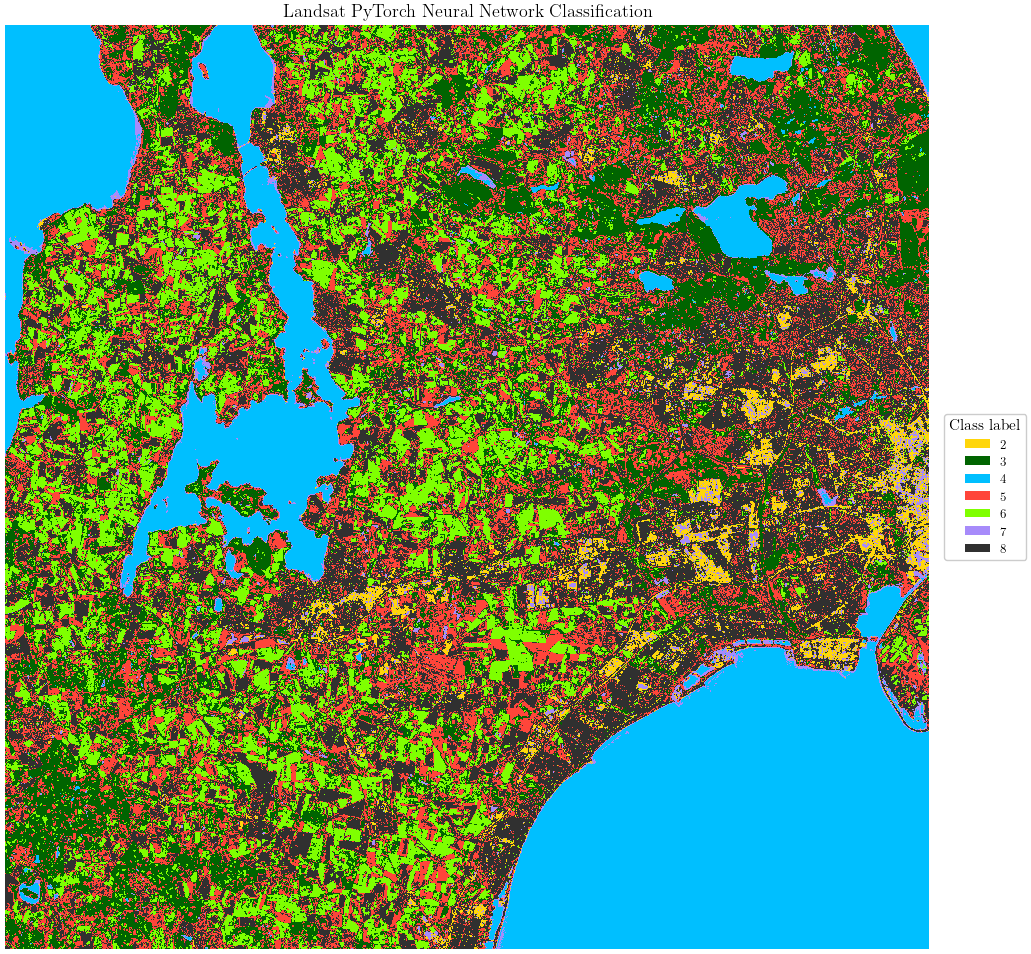

In [22]:
# implementing deep neural network
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from pathlib import Path
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report

torch.manual_seed(69)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
hidden_activation = 'relu'  # Change to 'sigmoid' for sigmoid hidden layers.
activation = {'relu': nn.ReLU, 'sigmoid': nn.Sigmoid}[hidden_activation]
print('Training device:', device)

# Fit preprocessing on training data only.
dnn_scaler = StandardScaler()
X_train_nn = dnn_scaler.fit_transform(X_train).astype('float32')
X_val_nn = dnn_scaler.transform(X_val).astype('float32')

dnn_encoder = LabelEncoder()
y_train_nn = dnn_encoder.fit_transform(y_train)
y_val_nn = dnn_encoder.transform(y_val)
n_classes = len(dnn_encoder.classes_)

train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train_nn),
                  torch.as_tensor(y_train_nn, dtype=torch.long)),
    batch_size=4096, shuffle=True, num_workers=0,
)
val_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_val_nn),
                  torch.as_tensor(y_val_nn, dtype=torch.long)),
    batch_size=4096, shuffle=False, num_workers=0,
)

# The model returns one sigmoid score for each original class.
dnn = nn.Sequential(
    nn.Linear(X_train_nn.shape[1], 64), activation(),
    nn.Linear(64, 32), activation(),
    nn.Linear(32, 16), activation(),
    nn.Linear(16, n_classes),
    nn.Sigmoid(),
).to(device)

# This view shares the same weights and exposes scores before sigmoid.
# BCEWithLogitsLoss applies sigmoid internally for stable training.
logit_model = dnn[:-1]
criterion = nn.BCEWithLogitsLoss(reduction='none')
optimizer = torch.optim.Adam(dnn.parameters(), lr=0.001)

# Apply the same rare-class weights to training and validation loss.
weights = compute_class_weight(
    class_weight='balanced', classes=np.arange(n_classes), y=y_train_nn,
)
class_weights = torch.as_tensor(weights, dtype=torch.float32, device=device)


def run_epoch(loader, training):
    dnn.train(training)
    total_loss, total_correct, total_samples = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            targets = nn.functional.one_hot(yb, num_classes=n_classes).float()
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = logit_model(xb)
            per_sample_loss = criterion(logits, targets).mean(dim=1)
            loss = (per_sample_loss * class_weights[yb]).mean()
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(yb)
            total_correct += (logits.argmax(dim=1) == yb).sum().item()
            total_samples += len(yb)
    return total_loss / total_samples, total_correct / total_samples


# Stop when weighted validation loss stops improving; restore the best model.
max_epochs, patience = 30, 5
best_loss, epochs_without_improvement = float('inf'), 0
best_state = {name: value.detach().cpu().clone()
              for name, value in dnn.state_dict().items()}
history = []
for epoch in range(1, max_epochs + 1):
    train_loss, train_accuracy = run_epoch(train_loader, training=True)
    val_loss, val_accuracy = run_epoch(val_loader, training=False)
    history.append(dict(epoch=epoch, loss=train_loss, accuracy=train_accuracy,
                        val_loss=val_loss, val_accuracy=val_accuracy))
    print(f'Epoch {epoch:02d}: loss={train_loss:.4f}, '
          f'accuracy={train_accuracy:.4f}, val_loss={val_loss:.4f}, '
          f'val_accuracy={val_accuracy:.4f}')
    if val_loss < best_loss:
        best_loss, epochs_without_improvement = val_loss, 0
        best_state = {name: value.detach().cpu().clone()
                      for name, value in dnn.state_dict().items()}
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print('Early stopping.')
            break

dnn.load_state_dict(best_state)
dnn.eval()

# The full model includes sigmoid. Predict in batches, then restore original labels.
dnn.eval()
score_batches = []
with torch.inference_mode():
    for xb, _ in val_loader:
        score_batches.append(dnn(xb.to(device)).cpu().numpy())
val_scores = np.concatenate(score_batches, axis=0)
del score_batches
y_pred_nn = dnn_encoder.inverse_transform(val_scores.argmax(axis=1))

print('DNN accuracy:', accuracy_score(y_val, y_pred_nn))
print('DNN balanced accuracy:', balanced_accuracy_score(y_val, y_pred_nn))
print(classification_report(
    y_val, y_pred_nn, labels=dnn_encoder.classes_, zero_division=0,
))

# Transform and predict in batches to avoid scaling the entire area at once.
unknown_area = pd.read_csv('data/landsat_area.csv', header=None)
encoded_predictions = np.empty(len(unknown_area), dtype=np.int32)
area_batch_size = 65536
dnn.eval()
with torch.inference_mode():
    for start in range(0, len(unknown_area), area_batch_size):
        stop = min(start + area_batch_size, len(unknown_area))
        batch = dnn_scaler.transform(unknown_area.iloc[start:stop]).astype('float32')
        scores = dnn(torch.from_numpy(batch).to(device))
        encoded_predictions[start:stop] = scores.argmax(dim=1).cpu().numpy()

predictions_nn = dnn_encoder.inverse_transform(encoded_predictions)
image_nn = encoded_predictions.reshape(3000, 3000)
labels_nn = dnn_encoder.classes_
counts_nn = np.bincount(encoded_predictions, minlength=len(labels_nn))

# RF uses class_colors directly.
# DNN uses the SAME colors in its encoder's class order.
labels_nn = dnn_encoder.classes_
palette_nn = [class_colors[int(label)] for label in labels_nn]
colors_nn = palette_nn.copy()

fig, ax = plt.subplots(figsize=(12, 12))
ax.imshow(
    image_nn, cmap=ListedColormap(colors_nn),
    norm=BoundaryNorm(np.arange(len(labels_nn) + 1) - 0.5, len(labels_nn)),
    interpolation='nearest',
)
ax.axis('off')
ax.set_title('Landsat PyTorch Neural Network Classification')
ax.legend(
    handles=[Patch(facecolor=colors_nn[i], label=str(label))
             for i, label in enumerate(labels_nn)],
    title='Class label', loc='center left', bbox_to_anchor=(1.01, 0.5),
)
Path('output').mkdir(parents=True, exist_ok=True)
fig.savefig('output/landsat_neural_network.png', dpi=300, bbox_inches='tight')
plt.show()